# Morgan Fingerprint Educational Implementation
- To better understand how Morgan Fingerprints work internally, I created a Python implementation while studying the RDKit source code.
- Although RDKit provides a convenient API for generating Morgan Fingerprints, the underlying calculations are often hidden from view.
- This notebook follows the fingerprint generation process step by step, including:
    - Atom Invariant generation
    - Neighborhood expansion
    - Morgan Identifier calculation
    - BitInfoMap construction
- Intermediate results can also be displayed, making it easier to observe what happens at each stage of the calculation.
- This implementation is a personal learning exercise intended to help understand the Morgan Fingerprint algorithm. It is not intended to be a complete port or replacement for RDKit.
- The code was tested in the following environment:
    - Python 3.10.18
    - RDKit 2025.03.5
    - pandas 2.3.1
- `MyGetMorganIdentifier()` returns a `DataFrame` containing Morgan Identifiers and Atom Neighborhoods.
    - Each row corresponds to an atom index.
    - The `radius` columns (integers) contain Morgan Identifiers.
    - The `radius + '_env'` columns contain Atom Neighborhoods, represented as integers generated from a bit vector in which the positions corresponding to bond indices contained in the Atom Environment are set to 1.
    - An Atom Environment is defined by a center atom index and a radius.
    - Morgan Identifiers corresponding to redundant Atom Environments, which are normally removed by RDKit, are also included in the output.
- Passing the resulting `DataFrame` to `MyGetBitInfoMap()` generates a `BitInfoMap` equivalent to RDKit's output, where redundant Atom Environments have been removed.
- Passing the resulting `BitInfoMap` to `MyGetFingerprint()` generates a fixed-length fingerprint equivalent to the Morgan Fingerprint produced by RDKit.
## Notes
- **Some cells depend on results generated in previous cells. Please execute the notebook sequentially from top to bottom.**
## Reference RDKit Source Code
- Morgan Fingerprint
    - https://github.com/rdkit/rdkit/blob/master/Code/GraphMol/Fingerprints/FingerprintUtil.cpp
    - https://github.com/rdkit/rdkit/blob/master/Code/GraphMol/Fingerprints/MorganGenerator.cpp
- Hash Functions
    - https://github.com/rdkit/rdkit/blob/master/Code/RDGeneral/hash/hash.hpp

In [1]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Chem import rdMolDescriptors # for GetConnectivityInvariants
from rdkit.Chem import rdCIPLabeler
from rdkit.DataStructs.cDataStructs import ExplicitBitVect
import pandas as pd
from IPython.display import SVG # to display molecules in jupyter notebook
from collections import defaultdict

## Table of Contents
0. Basics of Morgan Fingerprints
1. Calculating Morgan Identifiers for radius=0
2. Calculating Morgan Identifiers for radius>0
3. Removing Redundant Atom Environments
4. Converting Morgan Fingerprints to a Fixed-Length Representation
5. Examples of Stereochemistry and Isotopes

## 0. Basics of Morgan Fingerprints

- Morgan fingerprints are generated from atom environments in a molecule.
- An atom environment is defined by a center atom and a radius.
    - The radius specifies how many bond hops from the center atom are included in the atom environment.
    - An atom environment is usually represented as `(center atom index, radius)`.
        - For example, `(2, 1)` represents the atom environment centered on atom index 2 and including atoms up to one bond away.
- A Morgan Identifier is calculated for each atom environment.
    - In RDKit, Morgan Identifiers are represented as unsigned 32-bit integers.
    - A Morgan Identifier is calculated from the atomic and bond information contained in the corresponding atom environment.
    - Atom environments with the same information produce the same Morgan Identifier.
    - Different atom environments usually produce different Morgan Identifiers.
        - However, this is not mathematically guaranteed.
        -  Different atom environments may occasionally generate the same Morgan Identifier due to hash collisions.
- Morgan fingerprints are constructed from Morgan Identifiers generated from atom environments.
    - One representation is a bit-vector fingerprint indicating whether each Morgan Identifier is present in the molecule.
    - Another representation is a count fingerprint indicating how many times each Morgan Identifier appears in the molecule.
- In the following sections, we'll generate Morgan Fingerprints with RDKit and take a closer look at the information contained within them.

### Example of a Morgan Fingerprint in RDKit

- Let us generate a Morgan fingerprint for propanol using RDKit.
    - The fingerprint generated here is the basic fingerprint before conversion to a fixed-length bit vector.
        - We obtain the occurrence count of each Morgan Identifier.
        - A fixed-length bit-vector fingerprint is derived from this information (described in Section 4).
    - Conceptually, this fingerprint can be viewed as a very large count vector, but in practice only non-zero elements are stored.
        - Therefore, we use `fp.GetNonzeroElements()` to display only Morgan Identifiers corresponding to atom environments that actually occur in the molecule.

In [2]:
mol = Chem.MolFromSmiles("CCCO")
fpgen_r2 = rdFingerprintGenerator.GetMorganGenerator(radius=2) # Generator for radius=2 Morgan Fingerprints
ao = rdFingerprintGenerator.AdditionalOutput() # Specify additional output
ao.AllocateBitInfoMap() # Store BitInfoMap in the additional output
fp = fpgen_r2.GetSparseCountFingerprint(mol, additionalOutput=ao) # Generate the Morgan Fingerprint
for key in fp.GetNonzeroElements(): # Use GetNonzeroElements() to keep only Atom Environments that are present
    print(f"MorganIdentifier= {key} count= {fp[key]}")

MorganIdentifier= 864662311 count= 1
MorganIdentifier= 1173125914 count= 1
MorganIdentifier= 1365892349 count= 1
MorganIdentifier= 1535166686 count= 1
MorganIdentifier= 2245384272 count= 2
MorganIdentifier= 2246728737 count= 1
MorganIdentifier= 3542456614 count= 1
MorganIdentifier= 4023654873 count= 1


- We can see that 8 distinct Morgan Identifiers are obtained.
    - Two atom environments correspond to the Morgan Identifier `2245384272`.
    - Each of the remaining Morgan Identifiers corresponds to a single atom environment.
- Next, let us examine which atom environments correspond to these Morgan Identifiers.
    - In RDKit, this information can be obtained using `ao.GetBitInfoMap()`.

MorganIdentifier= 864662311  ((3, 0),)
MorganIdentifier= 1173125914  ((1, 1),)
MorganIdentifier= 1365892349  ((2, 2),)
MorganIdentifier= 1535166686  ((3, 1),)
MorganIdentifier= 2245384272  ((1, 0), (2, 0))
MorganIdentifier= 2246728737  ((0, 0),)
MorganIdentifier= 3542456614  ((0, 1),)
MorganIdentifier= 4023654873  ((2, 1),)


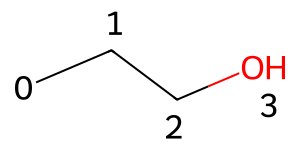

In [3]:
BitInfoMap = ao.GetBitInfoMap()
for key in BitInfoMap:
    print(f"MorganIdentifier= {key}  {BitInfoMap[key]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

- For each Morgan Identifier, the corresponding atom environment is displayed in the form `(center atom index, radius)`.
    - For example, the Morgan Identifier `864662311` corresponds to `(3, 0)`.
        - This atom environment consists only of atom index 3 itself.
    - The Morgan Identifier `1173125914` corresponds to `(1, 1)`.
    - The Morgan Identifier `2245384272` corresponds to both `(1, 0)` and `(2, 0)`.
        - In this case, the same Morgan Identifier is obtained from two different atom environments.
- In this way, we can determine which atom environments in the molecule correspond to each Morgan Identifier.
- The most important step in generating a Morgan fingerprint is the calculation of Morgan Identifiers for atom environments.
- In the following sections, we will follow the calculation process step by step and examine how Morgan Identifiers are generated.

## 1. Calculating Morgan Identifiers for radius=0
- Morgan Identifiers are calculated in the order radius=0, 1, 2, ...
    - A radius=0 Morgan Identifier is calculated using only information about the atom itself.
    - A radius>0 Morgan Identifier is calculated using the Morgan Identifier from the previous radius.
        - In other words, the Morgan Identifier at radius=n is calculated from the Morgan Identifier at radius=n-1.
- Let us first examine how a radius=0 Morgan Identifier is calculated.
- In this notebook, we follow the calculation using the following steps.
    - For each atom, an Atom Component is constructed from atomic information.
    - Each Atom Component is hashed to calculate an Atom Invariant.
        - An Atom Invariant is represented as an unsigned 32-bit integer.
    - The calculated Atom Invariant is used as the radius=0 Morgan Identifier.

### Atom Component
- To calculate Morgan Identifiers, we first construct Atom Components.
- An Atom Component is a sequence of integers (represented as a Python list in this notebook) containing the atomic information used for Morgan Identifier calculation.
    1. Atomic number
    2. Total degree (number of neighboring atoms including hydrogens)
    3. Number of bonded hydrogens
    4. Formal charge
    5. Difference from the standard atomic mass
        - The mass difference is converted to an integer using `int()`.
    6. Ring membership flag
        - A value of `1` is appended only if the atom belongs to a ring.
        - Therefore, the list length is 6 for ring atoms and 5 for non-ring atoms.
- Atom Components have the following form:
    - `[atomic number, degree, hydrogen count, formal charge, isotope difference (, ring membership flag)]`
- `MyGetAtomComponents()` is a function that returns the Atom Components for all atoms in a molecule.

In [4]:
def MyGetAtomComponents(mol, verbose=0):
    # Create a list of Atom Components for all atoms
    ptable = Chem.GetPeriodicTable()
    AtomComponents = []
    for atom in mol.GetAtoms():
        atomic_num = atom.GetAtomicNum()
        total_degree = atom.GetTotalDegree()
        total_num_hs = atom.GetTotalNumHs(True)
        formal_charge = atom.GetFormalCharge()
        delta_mass = int( atom.GetMass() - ptable.GetAtomicWeight(atomic_num) )
        components = [ atomic_num, total_degree, total_num_hs, formal_charge, delta_mass ]
        if atom.IsInRing():
            components.append(1)
        if verbose:
            print(f"atom= {atom.GetIdx()}  AtomComponent= {components}")
        AtomComponents.append(components)
    return AtomComponents

- Let us calculate the Atom Components for propanol.

In [5]:
mol = Chem.MolFromSmiles("CCCO")
AtomComponents = MyGetAtomComponents(mol, verbose=1)

atom= 0  AtomComponent= [6, 4, 3, 0, 0]
atom= 1  AtomComponent= [6, 4, 2, 0, 0]
atom= 2  AtomComponent= [6, 4, 2, 0, 0]
atom= 3  AtomComponent= [8, 2, 1, 0, 0]


### Calculating Atom Invariants from Atom Components (= Morgan Identifiers at radius=0)
#### Hash Calculation
- Atom Invariants are represented as unsigned 32-bit integers.
- Hashing is used to convert the multiple pieces of information contained in an Atom Component into a single integer value.
- RDKit uses a hashing scheme based on the same idea as Boost's `hash_combine()`.
- For learning purposes, a Python implementation is provided.
    - `hash_combine()` is the core function. It returns a new hash value by incorporating a new value (`value`) into an existing hash (`seed`).
        - It combines information using bit shifts, addition, and XOR operations.
        - It uses the magic number `0x9e3779b9`, derived from the fractional part of the Golden Ratio, to help small changes in the input propagate throughout the hash value.
    - `vector_hash()` calculates a cumulative hash value from a sequence of numbers.
    - `pair_hash()` calculates a hash value from two numbers (used later).

In [6]:
def hash_combine(seed, value): # Boost hash_combine function
    MASK32 = 0xffffffff # Python integers have arbitrary precision, so MASK32 and bitwise AND are used to emulate uint32_t
    seed ^= ( value + 0x9e3779b9 + ( (seed << 6) & MASK32) + (seed >> 2) )
    return seed & MASK32 

def vector_hash(values, verbose=0): # Calculate a cumulative hash value from multiple values
    seed = 0
    if verbose:
        print(f'seed={seed}')
    for value in values:
        org_seed = seed
        seed = hash_combine( seed, value )
        if verbose:
            print(f'combine seed {org_seed}, value {value} -> seed {seed}')
    return seed

def pair_hash(a, b): # Calculate a hash value from two values
    seed = 0
    seed = hash_combine(seed, a)
    seed = hash_combine(seed, b)
    return seed

- `vector_hash()` is used to calculate Atom Invariants from Atom Components.
    - When a sequence of numbers is passed to `vector_hash()`, an unsigned 32-bit integer is returned as the hash value.
- As an example, let us examine how the Atom Component `[6, 4, 3, 0, 0]` for atom 0 in propanol is hashed.

In [7]:
print(f"hash value = {vector_hash([6, 4, 3, 0, 0], verbose=1)}")

seed=0
combine seed 0, value 6 -> seed 2654435775
combine seed 2654435775, value 4 -> seed 3449077331
combine seed 3449077331, value 3 -> seed 4216881219
combine seed 4216881219, value 0 -> seed 1215638218
combine seed 1215638218, value 0 -> seed 2246728737
hash value = 2246728737


- The final Atom Invariant, `2246728737`, becomes the radius=0 Morgan Identifier for atom 0 in propanol.
- `MyGetAtomInvariants()` is a function that calculates Atom Invariants for all atoms from their Atom Components.

In [8]:
def MyGetAtomInvariants(AtomComponents):
    # Create a list of Atom Invariants from a list of Atom Components
    AtomInvariants=[]
    for components in AtomComponents:
        AtomInvariants.append(vector_hash(components))
    return AtomInvariants

- RDKit provides `rdMolDescriptors.GetConnectivityInvariants()`, which returns the radius=0 Atom Invariants.
- Let us compare the Atom Invariants calculated by RDKit with those calculated by `MyGetAtomInvariants()`.

In [9]:
mol = Chem.MolFromSmiles("CCCO")
rdkit_invars = rdMolDescriptors.GetConnectivityInvariants(mol) # RDKit function for obtaining Atom Invariants
print('GetConnectivityInvariants(mol)',rdkit_invars)
AtomComponents = MyGetAtomComponents(mol)
AtomInvariants = MyGetAtomInvariants(AtomComponents)
for atom in mol.GetAtoms():
    a_idx = atom.GetIdx()
    print(
        f"atom={a_idx} ",
        f"components={AtomComponents[a_idx]} ",
        f"atomInvariant={AtomInvariants[a_idx]} ",
        f"rdkit={rdkit_invars[a_idx]}"
    )

GetConnectivityInvariants(mol) [2246728737, 2245384272, 2245384272, 864662311]
atom=0  components=[6, 4, 3, 0, 0]  atomInvariant=2246728737  rdkit=2246728737
atom=1  components=[6, 4, 2, 0, 0]  atomInvariant=2245384272  rdkit=2245384272
atom=2  components=[6, 4, 2, 0, 0]  atomInvariant=2245384272  rdkit=2245384272
atom=3  components=[8, 2, 1, 0, 0]  atomInvariant=864662311  rdkit=864662311


- We can see that the same values are obtained for all atoms.
- This confirms that the Atom Invariants in this notebook are calculated in the same manner as RDKit.
- The calculated Atom Invariants serve as the Morgan Identifiers at radius=0.
- By organizing the resulting Morgan Identifiers together with their corresponding atom environments, we can construct the BitInfoMap for radius=0.

## 2. Calculating Morgan Identifiers for radius>0
- Morgan Identifiers for radius>0 are calculated using the Atom Invariants obtained at the previous radius.
- The Morgan Identifier corresponding to an atom environment at radius=n is calculated roughly as follows:
    - Construct Neighbor information from the Atom Invariants at radius=n−1.
        - Neighbor information is a list of `(Bond Invariant, Atom Invariant)` pairs for neighboring atoms.
    - Construct stereochemical information (`LooksChiral`).
        - This is an integer value representing stereochemical information associated with an atom.
    - Perform hash calculations while adding the following information in sequence:
        1. Set the initial value to `radius - 1`.
        2. Add and hash the Atom Invariant of the center atom.
        3. Add and hash the Neighbor information.
        4. Add and hash stereochemical information when applicable.
- The resulting Atom Invariant becomes the Morgan Identifier at radius=n.

### Bond Invariant

- `MyGetBondInvariants()` calculates Bond Invariants for all bonds in a molecule.
- To calculate Morgan Identifiers for radius>0, information describing how atoms are connected is required.
    - Therefore, a Bond Invariant is calculated for each bond.
- Bond Invariants are calculated as follows:
    - The initial value is `1`.
        - This is the simplest value representing the presence of a bond when bond type and stereochemistry are not considered.
        - This case is not used further in this notebook.
    - If stereochemistry is not used, if the bond is not a double bond, or if stereochemical information is unavailable, `int(bond.GetBondType())` is used.
        - Single bond: `1`
        - Double bond: `2`
        - Triple bond: `3`
        - Aromatic bond: `12`
        - Other bond types use integer values defined by RDKit.
    - Otherwise, a value incorporating both bond type and stereochemistry is used:
        - `100 + 10 * int(bond.GetBondType()) + int(bond.GetStereo())`
        - `bond.GetStereo()` returns stereochemical information for the bond.
            - `0` : STEREONONE
            - `1` : STEREOANY
            - `2` : STEREOZ
            - `3` : STEREOE
- Details of `BondType` and `Stereo` can be found in the RDKit Bond class documentation.
    - https://www.rdkit.org/docs/cppapi/classRDKit_1_1Bond.html

In [10]:
def MyGetBondInvariants(mol, useBondTypes=True, useChiral=False, verbose=0):
    # Create a list of Bond Invariants for all bonds
    stereoOffset = 100
    bondTypeOffset = 10
    BondInvariants = []
    for bond in mol.GetBonds():
        invariant = 1 # Initial value
        if useBondTypes:
            if ( not useChiral or bond.GetBondType() != Chem.BondType.DOUBLE or bond.GetStereo() == Chem.BondStereo.STEREONONE ):
                invariant = int(bond.GetBondType()) # If chirality is not used, the bond is not a double bond, or stereo information is not available
            else:
                invariant = ( stereoOffset + bondTypeOffset * int(bond.GetBondType()) + int(bond.GetStereo()) )
        if verbose:
            print(f'bond={bond.GetIdx()} bondInvariants={invariant}  ' + \
                  f'bond.GetBondType={int(bond.GetBondType())}  bond.GetStereo={int(bond.GetStereo())}')
        BondInvariants.append(invariant)
    return BondInvariants

- Let us calculate Bond Invariants for propanol.

In [11]:
mol = Chem.MolFromSmiles("CCCO")
BondInvariants = MyGetBondInvariants(mol,verbose=1)

bond=0 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0
bond=1 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0
bond=2 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0


- Since all bonds are single bonds and no stereochemical information is present, the Bond Invariant for every bond is `1`.
- Next, let us calculate Bond Invariants for trans-2-butene.
    - When `useChiral=False`, stereochemical information is ignored.
    - RDKit Morgan Fingerprints also ignore stereochemistry by default.

useChiral=False (default)
bond=0 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0
bond=1 bondInvariants=2  bond.GetBondType=2  bond.GetStereo=3
bond=2 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0
useChiral=True
bond=0 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0
bond=1 bondInvariants=123  bond.GetBondType=2  bond.GetStereo=3
bond=2 bondInvariants=1  bond.GetBondType=1  bond.GetStereo=0


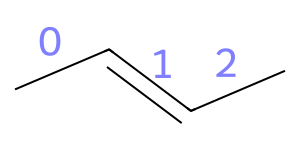

In [12]:
mol = Chem.MolFromSmiles("C\C=C\C")
print("useChiral=False (default)")
BondInvariants = MyGetBondInvariants(mol, verbose=1)
print("useChiral=True")
BondInvariants = MyGetBondInvariants(mol, useChiral=True, verbose=1)
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addBondIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

- Bond 1 is a double bond and has E/Z stereochemical information.
- When `useChiral=False`, only the bond type is used, so the Bond Invariant is `2`.
- When `useChiral=True`, stereochemical information is also included: <br>
  `100 + 10 × 2 + 3 = 123` <br>
  Therefore, the Bond Invariant becomes `123`.

### Neighbor Information
- `MyGetNeighbors()` is a function that constructs Neighbor information for all atoms in a molecule.
- Neighbor information is a list describing neighboring atoms and the bonds connecting them to the center atom.
    - Each element is represented as `(Bond Invariant, Atom Invariant)`.
    - The Bond Invariant describes the bond connecting the center atom and the neighboring atom.
    - The Atom Invariant is the radius=n−1 Atom Invariant of the neighboring atom.
- The Neighbor information for each atom is sorted lexicographically by `(Bond Invariant, Atom Invariant)`.
    - Comparison is performed first using the Bond Invariant and then using the Atom Invariant.
    - In the subsequent hash calculation, the order in which information is added affects the result.
    - Therefore, sorting is performed to obtain consistent results independent of atom ordering.
    - The sorted Neighbor information is also used later when determining stereochemical information.
- `MyGetNeighbors()` constructs and returns Neighbor information for all atoms.

In [13]:
def MyGetNeighbors(mol, AtomInvariants, BondInvariants, verbose=0):
    # Create Neighbor information (Bond Invariant, Atom Invariant) for all atoms
    Neighbors = []
    for atom in mol.GetAtoms():
        neigh = []
        for bond in atom.GetBonds(): # Loop over all bonds connected to the atom
            other = bond.GetOtherAtom(atom) # Get the neighboring atom
            neigh.append( (BondInvariants[bond.GetIdx()] , AtomInvariants[other.GetIdx()] ) )
        neigh.sort() # # Sort the resulting Neighbor information
        if verbose:
            print(f"atom= {atom.GetIdx()}  neighbor= {neigh}")
        Neighbors.append(neigh)
    return Neighbors

- Let us calculate Neighbor information for propanol.
    - Atom 0 is connected to atom 1 by a single bond, so its Neighbor information is `[(1, 2245384272)]`.
    - Atom 1 is connected to atoms 0 and 2 by single bonds, so its Neighbor information is `[(1, 2245384272), (1, 2246728737)]`.

In [14]:
mol = Chem.MolFromSmiles("CCCO")
AtomComponents = MyGetAtomComponents(mol)
AtomInvariants = MyGetAtomInvariants(AtomComponents)
BondInvariants = MyGetBondInvariants(mol)
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants, verbose=1)

atom= 0  neighbor= [(1, 2245384272)]
atom= 1  neighbor= [(1, 2245384272), (1, 2246728737)]
atom= 2  neighbor= [(1, 864662311), (1, 2245384272)]
atom= 3  neighbor= [(1, 2245384272)]


- In each tuple, the first value is the Bond Invariant and the second value is the radius=n−1 Atom Invariant of the neighboring atom.
- Next, let us calculate Neighbor information for trans-2-butene.
    - Unless `useChiral=True` is specified, stereochemical information is not incorporated into the Bond Invariant.

In [15]:
mol = Chem.MolFromSmiles("C\C=C\C")
AtomComponents = MyGetAtomComponents(mol)
AtomInvariants = MyGetAtomInvariants(AtomComponents)
print("useChiral=False (default)")
BondInvariants = MyGetBondInvariants(mol)
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants, verbose=1)
print("useChiral=True")
BondInvariants = MyGetBondInvariants(mol, useChiral=True)
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants, verbose=1)

useChiral=False (default)
atom= 0  neighbor= [(1, 2246703798)]
atom= 1  neighbor= [(1, 2246728737), (2, 2246703798)]
atom= 2  neighbor= [(1, 2246728737), (2, 2246703798)]
atom= 3  neighbor= [(1, 2246703798)]
useChiral=True
atom= 0  neighbor= [(1, 2246703798)]
atom= 1  neighbor= [(1, 2246728737), (123, 2246703798)]
atom= 2  neighbor= [(1, 2246728737), (123, 2246703798)]
atom= 3  neighbor= [(1, 2246703798)]


- When `useChiral=False`, the double bond is represented by Bond Invariant `2`.
- When `useChiral=True`, E/Z stereochemical information is incorporated into the Bond Invariant, causing its value to change to `123`.
- As a result, the Neighbor information also changes.
- This difference propagates into the subsequent hash calculation and ultimately affects the resulting Morgan Identifiers.

### Stereochemical Information (LooksChiral)
- `MyGetLooksChirals()` calculates stereochemical information (`LooksChiral`) for all atoms in a molecule.
- Before calculating this information, `rdCIPLabeler.AssignCIPLabels(mol)` must be executed to assign CIP stereochemical labels to the atoms.
- The stereochemical value for each atom is determined as follows:
    - `0` if stereochemistry is not used.
        - Morgan Fingerprints do not use stereochemistry by default.
    - `0` if no CIP stereochemical information is available.
    - `0` if the atom is not considered a potential stereocenter.
    - Otherwise, a value is assigned according to `atom.GetProp("_CIPCode")`:
        - `"R"` → `3`
        - `"S"` → `2`
        - Otherwise → `1`
- These integer values are later incorporated into the Morgan Identifier calculation.
#### Determining Potential Stereocenters
- Whether an atom is considered a potential stereocenter is determined by `morgan_looks_chiral_atom()`.
- The decision procedure is as follows:
    - Return `False` if no stereochemical specification exists for the atom.
    - Return `False` if any bond connected to the atom is not a single bond.
    - Return `False` if duplicate Atom Invariants exist among neighboring atoms.
        - The sorted Neighbor information is examined sequentially.
        - If the same Atom Invariant appears twice in succession, the atom is not considered a potential stereocenter.
    - Otherwise return `True`.
- Because the Neighbor information has already been sorted, duplicate Atom Invariants can be detected efficiently.

In [16]:
def morgan_looks_chiral_atom(atom, Neighbor):
    # Determine whether the atom is chiral based on the Atom Invariants in Neighbor information
    if atom.GetChiralTag() == Chem.rdchem.ChiralType.CHI_UNSPECIFIED:
        return False # No stereochemical specification is present for this atom
    prev_inv = None
    for bond_inv, atom_inv in Neighbor: # Assumes that Neighbor information has already been sorted
        if bond_inv != 1: # If a non-single bond is present, the atom is not chiral
            return False
        if prev_inv is not None and atom_inv == prev_inv: # If duplicate Atom Invariants exist among neighbors, the atom is not chiral
            return False
        prev_inv = atom_inv
    return True

def MyGetLooksChirals(mol, Neighbors, useChiral=False):
    # Create a list of chirality information (LooksChiral) for all atoms
    LooksChirals = []
    for atom, neigh in zip(mol.GetAtoms(), Neighbors):
        if not useChiral: # When chirality is not used
            LooksChirals.append(0) # Append 0
            continue
        if not morgan_looks_chiral_atom(atom, neigh): # No stereochemical specification or duplicate Neighbors exist (not a chiral center)
            LooksChirals.append(0) # Append 0
            continue
        cip = atom.GetProp("_CIPCode") if atom.HasProp("_CIPCode") else "" # rdCIPLabeler.AssignCIPLabels(mol) must be called beforehand
        if cip == "R":
            LooksChirals.append(3) # Append 3 for R configuration
        elif cip == "S":
            LooksChirals.append(2) # Append 2 for S configuration
        else:
            LooksChirals.append(1) # Append 1 for all other cases
    return LooksChirals

#### Example: Propanol
- Let us calculate the stereochemical information for propanol.
- Since stereochemistry is not used by default, all atoms receive the value `0`.

In [17]:
mol = Chem.MolFromSmiles("CCCO")
AtomComponents = MyGetAtomComponents(mol)
AtomInvariants = MyGetAtomInvariants(AtomComponents)
BondInvariants = MyGetBondInvariants(mol)
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
print(MyGetLooksChirals(mol, Neighbors))

[0, 0, 0, 0]


#### Example: A Molecule with a Stereocenter
- As an example containing a stereocenter, consider `CC[C@@](F)(Cl)Br`.
- When `useChiral=False`, stereochemical information is not used, so all atoms receive the value `0`.
- When `useChiral=True`, stereochemical information from the stereocenter is incorporated.
    - In this molecule, atom 2 has the R configuration, so the value `3` is assigned.

In [18]:
mol = Chem.MolFromSmiles("CC[C@@](F)(Cl)Br")
rdCIPLabeler.AssignCIPLabels(mol)
AtomComponents = MyGetAtomComponents(mol)
AtomInvariants = MyGetAtomInvariants(AtomComponents)
print("useChiral=False (default)")
BondInvariants = MyGetBondInvariants(mol)
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
print(MyGetLooksChirals(mol, Neighbors))
print("useChiral=True")
BondInvariants = MyGetBondInvariants(mol, useChiral=True)
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
print(MyGetLooksChirals(mol, Neighbors, useChiral=True))

useChiral=False (default)
[0, 0, 0, 0, 0, 0]
useChiral=True
[0, 0, 3, 0, 0, 0]


- When stereochemistry is enabled, these values are incorporated into the Morgan Identifier calculation.

### Calculating Morgan Identifiers at Radius 1
- We now have all the information required to calculate Morgan Identifiers at radius=1.
- The following information is required for each atom:
    - `layer`
        - A value used to distinguish the current radius being calculated.
        - The value `radius - 1` is used.
        - For radius=1, this value is `0`.
    - `CenterInvariant`
        - The Atom Invariant of the center atom.
    - `Neighbor`
        - The Neighbor information of the center atom.
    - `LooksChiral`
        - The stereochemical information of the center atom.
- `MyRadiusHash()` hashes these values to generate a new Atom Invariant.
- The calculation proceeds as follows:
    1. Initialize the hash value with `layer`.
    2. Add and hash the Atom Invariant of the center atom.
    3. Add and hash the Neighbor information.
        - The Neighbor information is already sorted.
        - Entries are processed in that order.
        - Each `(Bond Invariant, Atom Invariant)` pair is converted into a single integer using `pair_hash()`.
        - The resulting value is then added to the hash calculation.
    4. If `LooksChiral` is non-zero, add and hash that value as well.
- The final integer becomes a new Atom Invariant.
- This Atom Invariant serves as the Morgan Identifier at radius=1.
- `MyGetLayerMorganIdentifier()` takes the information for all atoms and returns the newly calculated Atom Invariants.

In [19]:
def MyRadiusHash(layer, CenterInvariant, Neighbor, LooksChiral, verbose=0):
    # Calculate a Morgan Identifier from layer, center atom Atom Invariant, Neighbor information, and chirality information
    seed = layer # Initialize the seed value
    if verbose:
        print(f'seed={seed}')
        org_seed = seed
    seed = hash_combine( seed, CenterInvariant ) # Add the center atom Atom Invariant
    if verbose:
        print(f'combine seed {org_seed}, value {CenterInvariant} -> seed {seed}')
        org_seed = seed
    i=0
    for bond_inv, neigh_inv in Neighbor: # Add Neighbor information
        ph = pair_hash( bond_inv, neigh_inv ) # Hash the Bond Invariant and Atom Invariant of the neighboring atom
        if verbose:
            print(f'hash Neighbor {i} ({bond_inv}, {neigh_inv}) -> {ph}')
        seed = hash_combine( seed, ph ) # Add the hashed Neighbor information
        if verbose:
            print(f'combine seed {org_seed}, value {ph} -> seed {seed}')
            org_seed = seed
        i += 1
    if LooksChiral != 0: # Add chirality information
        seed = hash_combine( seed, LooksChiral )
        if verbose:
            print(f'combine seed {org_seed}, value {ph} -> seed {seed}')
            org_seed = seed
    return seed

def MyGetLayerMorganIdentifier(layer, AtomInvariants, Neighbors, LooksChirals):
    # Create a list of Morgan Identifiers for all atoms at this layer
    MorganIdentifiers=[]
    for i, CenterInvariant in enumerate(AtomInvariants): # Loop over the Atom Invariants of all atoms
        MorganIdentifiers.append(MyRadiusHash(layer, CenterInvariant, Neighbors[i], LooksChirals[i]))
    return MorganIdentifiers

#### Example: Atom 1 in Propanol
- Let us calculate the radius=1 Atom Invariant for atom 1 in propanol.
- Passing the required information to `MyRadiusHash()` produces the new Atom Invariant `1173125914`.

In [20]:
layer = 0
CenterInvariant = 2245384272
Neighbor = [(1, 2245384272), (1, 2246728737)]
LooksChiral = 0
MyRadiusHash(layer, CenterInvariant, Neighbor, LooksChiral, verbose=1)

seed=0
combine seed 0, value 2245384272 -> seed 604852745
hash Neighbor 0 (1, 2245384272) -> 1196353357
combine seed 604852745, value 1196353357 -> seed 3587401153
hash Neighbor 1 (1, 2246728737) -> 1203329906
combine seed 3587401153, value 1203329906 -> seed 1173125914


1173125914

- This Atom Invariant becomes the radius=1 Morgan Identifier for atom 1.
#### Comparison with RDKit
- Let us calculate the radius=0 and radius=1 Atom Invariants (Morgan Identifiers) for propanol.
- Comparing them with the BitInfoMap generated by RDKit shows that the calculated Morgan Identifiers match.

In [21]:
mol = Chem.MolFromSmiles("CCCO")
AtomInvariants = MyGetAtomInvariants(MyGetAtomComponents(mol))
print("Atom Invariants calculated by this Python implementation")
print(f"radius=0  MorganIdentifiers={AtomInvariants}")
BondInvariants = MyGetBondInvariants(mol)

layer=0
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
LooksChirals = MyGetLooksChirals(mol, Neighbors)
MorganIdentifiers = MyGetLayerMorganIdentifier(layer, AtomInvariants, Neighbors, LooksChirals)
print(f"radius=1  MorganIdentifiers={MorganIdentifiers}")

print("Morgan Fingerprint generated by RDKit")
fpgen_r1 = rdFingerprintGenerator.GetMorganGenerator(radius=1) # Generator for radius=1 Morgan Fingerprints
fp = fpgen_r1.GetSparseCountFingerprint(mol, additionalOutput=ao) # Generate the Morgan Fingerprint
BitInfoMap = ao.GetBitInfoMap()
for rd in BitInfoMap:
    print(f"MorganIdentifier={rd}  {BitInfoMap[rd]}")

Atom Invariants calculated by this Python implementation
radius=0  MorganIdentifiers=[2246728737, 2245384272, 2245384272, 864662311]
radius=1  MorganIdentifiers=[3542456614, 1173125914, 4023654873, 1535166686]
Morgan Fingerprint generated by RDKit
MorganIdentifier=864662311  ((3, 0),)
MorganIdentifier=1173125914  ((1, 1),)
MorganIdentifier=1535166686  ((3, 1),)
MorganIdentifier=2245384272  ((1, 0), (2, 0))
MorganIdentifier=2246728737  ((0, 0),)
MorganIdentifier=3542456614  ((0, 1),)
MorganIdentifier=4023654873  ((2, 1),)


- We can confirm that the radius=0 and radius=1 Morgan Identifiers produced by this Python implementation are identical to those generated by RDKit.
#### Radius 2 Calculation
- Morgan Identifiers at radius=2 can be calculated in exactly the same way.
- In the example below, the Morgan Identifiers generated at radius=1 are used as the new Atom Invariants, and the calculation is performed with `layer=1`.

In [22]:
mol = Chem.MolFromSmiles("CCCO")
# radius = 0
AtomInvariants = MyGetAtomInvariants(MyGetAtomComponents(mol))
BondInvariants = MyGetBondInvariants(mol)
# radius = 1
layer=0
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
LooksChirals = MyGetLooksChirals(mol, Neighbors)
MorganIdentifiers = MyGetLayerMorganIdentifier(layer, AtomInvariants, Neighbors, LooksChirals)
# radius = 2
AtomInvariants = MorganIdentifiers # Use the radius=1 Morgan Identifiers as Atom Invariants and repeat the same procedure
layer=1
Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
LooksChirals = MyGetLooksChirals(mol, Neighbors)
MorganIdentifiers = MyGetLayerMorganIdentifier(layer, AtomInvariants, Neighbors, LooksChirals)
print("radius=2 Morgan Identifiers calculated by this Python implementation")
print(f"radius=2 MorganIdentifiers={MorganIdentifiers}")

print("Morgan Fingerprint generated by RDKit")
fpgen_r2 = rdFingerprintGenerator.GetMorganGenerator(radius=2) # Generator for radius=2 Morgan Fingerprints
fp = fpgen_r2.GetSparseCountFingerprint(mol, additionalOutput=ao) # Generate the Morgan Fingerprint
BitInfoMap = ao.GetBitInfoMap()
for rd in BitInfoMap:
    print(f"MorganIdentifier={rd}  {BitInfoMap[rd]}")

radius=2 Morgan Identifiers calculated by this Python implementation
radius=2 MorganIdentifiers=[1747430757, 2648393034, 1365892349, 3729693694]
Morgan Fingerprint generated by RDKit
MorganIdentifier=864662311  ((3, 0),)
MorganIdentifier=1173125914  ((1, 1),)
MorganIdentifier=1365892349  ((2, 2),)
MorganIdentifier=1535166686  ((3, 1),)
MorganIdentifier=2245384272  ((1, 0), (2, 0))
MorganIdentifier=2246728737  ((0, 0),)
MorganIdentifier=3542456614  ((0, 1),)
MorganIdentifier=4023654873  ((2, 1),)


- Looking at the calculated radius=2 Morgan Identifiers, we find that atom 2 produces the Morgan Identifier `1365892349`, matching RDKit's atom environment `(2, 2)`.
- On the other hand, the radius=2 Morgan Identifiers calculated for atoms 0, 1, and 3 do not appear in RDKit's output.
- This is because redundant atom environments are removed when constructing a Morgan Fingerprint.
- Examining the atom environments `(0, 2)`, `(1, 2)`, `(2, 2)`, and `(3, 2)`:
    - `(0, 2)` represents the same atom environment as `(1, 1)`, so the later-generated `(0, 2)` is discarded.
    - `(3, 2)` represents the same atom environment as `(2, 1)`, so the later-generated `(3, 2)` is discarded.
    - `(1, 2)` and `(2, 2)` both correspond to atom environments containing the same set of bonds. Only one of them is retained.
- As a result, only one of the four radius=2 atom environments is retained and the others are discarded.
- Next, we will see how equivalent atom environments are identified and why `(2, 2)` is the one that remains.

## 3. Removing Redundant Atom Environments
- In Morgan Fingerprints, redundant atom environments representing the same environment are removed.
- Whether two atom environments are considered identical is determined by the set of bonds contained in the environments.
- In this notebook, this bond set is represented as an atomNeighborhood.
- An atom environment is represented as `(center atom index, radius)`.
- An atomNeighborhood represents the set of bond indices contained in the atom environment as a bit vector and stores it as an integer.
    - For example, if bond indices 1, 2, and 3 are included, the resulting value is `14`.
    - The binary representation of `14` is `0b1110`, indicating that bit positions 1, 2, and 3 are set to 1 while bit position 0 is 0.
- Atom environments generated at each radius are stored in `allNeighborhoodsThisRound`.
    - This structure is used to compare atom environments generated at the same radius.
    - Each element has the form `(atomNeighborhood, MorganIdentifier, atomIdx)`.
- `allNeighborhoodsThisRound` is sorted and checked to determine whether an identical atomNeighborhood has already appeared.
- If the atomNeighborhood has already appeared, the corresponding atom environment is considered redundant and is removed.

### Constructing atomNeighborhood
- `MyGetInitatomNeighborhoods()` examines bonds adjacent to each atom and constructs the atomNeighborhood corresponding to radius=1 (layer=0).
- `MyGetatomNeighborhoods()` constructs atomNeighborhoods at radius=n+1 from atomNeighborhoods at radius=n.
- An atomNeighborhood at radius=n+1 is constructed by combining the radius=n atomNeighborhoods of the center atom and its neighboring atoms using bitwise OR operations.

In [23]:
def MyGetInitatomNeighborhoods(mol): 
    # Examine the bonds connected to each atom and create the initial Atom Neighborhoods
    atomNeighborhoods = []
    for atom in mol.GetAtoms():
        env=0
        for b_idx in [bond.GetIdx() for bond in atom.GetBonds()]:
            env |= (1 << b_idx) # Integer representation with bits corresponding to bond indices set to 1
        atomNeighborhoods.append(env)
    return atomNeighborhoods

def MyGetatomNeighborhoods(mol, atomNeighborhoods):
    # Create new Atom Neighborhoods for all atoms from existing Atom Neighborhoods
    environment_bitsets = [] # Store the newly generated Atom Neighborhoods
    for atom in mol.GetAtoms():
        env = atomNeighborhoods[atom.GetIdx()] # Start with the Atom Neighborhood of the center atom itself
        for neig_atom in atom.GetNeighbors():
            env |= atomNeighborhoods[neig_atom.GetIdx()] # Apply a bitwise OR operation with neighboring Atom Neighborhoods
        environment_bitsets.append(env)
    return environment_bitsets

- Let us calculate atomNeighborhoods for propanol at radius=1 and radius=2.
    - The radius=1 atom environment for atom 0 contains bond 0, so `atomNeighborhood=1 (=0b1)`.
    - The radius=2 atom environment for atom 0 contains bonds 0 and 1, so `atomNeighborhood=3 (=0b11)`.
    - The radius=1 atom environment for atom 1 contains bonds 0 and 1, so `atomNeighborhood=3 (=0b11)`.
    - The radius=2 atom environment for atom 1 contains bonds 0, 1, and 2, so `atomNeighborhood=7 (=0b111)`.

radius =1
atom= 0  atomNeighborhood= 1 = 0b1
atom= 1  atomNeighborhood= 3 = 0b11
atom= 2  atomNeighborhood= 6 = 0b110
atom= 3  atomNeighborhood= 4 = 0b100
radius =2
atom= 0  atomNeighborhood= 3 = 0b11
atom= 1  atomNeighborhood= 7 = 0b111
atom= 2  atomNeighborhood= 7 = 0b111
atom= 3  atomNeighborhood= 6 = 0b110


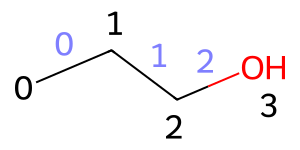

In [24]:
mol = Chem.MolFromSmiles("CCCO")
print("radius =1")
atomNeighborhoods = MyGetInitatomNeighborhoods(mol)
for i, env in enumerate(atomNeighborhoods):
    print(f"atom= {i}  atomNeighborhood= {env} = {bin(env)}")
print("radius =2")
atomNeighborhoods = MyGetatomNeighborhoods(mol, atomNeighborhoods)
for i, env in enumerate(atomNeighborhoods):
    print(f"atom= {i}  atomNeighborhood= {env} = {bin(env)}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addBondIndices = True
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

### Calculating Morgan Identifiers and atomNeighborhoods
- `MyGetMorganIdentifier()` performs all steps described so far.
- It calculates both the Morgan Identifiers and the corresponding atomNeighborhoods for each radius.
- When a non-zero value is specified for `verbose` (default: `0`), intermediate calculation details are displayed.
- To ignore stereochemistry, use `MyGetMorganIdentifier(mol, radius=2)`.
- To include stereochemistry, use `MyGetMorganIdentifier(mol, radius=2, includeChirality=True)`.
    - When `includeChirality=True` is specified, Morgan Identifiers are calculated with stereochemical information.
    - Internally, `rdCIPLabeler.AssignCIPLabels(mol)` is executed.
    - `BondInvariants = MyGetBondInvariants(mol, useChiral=True)` is executed.
    - `LooksChirals = MyGetLooksChirals(mol, Neighbors, useChiral=True)` is executed.
- The return value is a DataFrame.
    - Rows correspond to atom indices.
    - Columns `0`, `1`, `2`, ... contain Morgan Identifiers for each radius.
    - Columns `0_env`, `1_env`, `2_env`, ... contain the corresponding atomNeighborhoods.
    - All values in `0_env` are `0`.
        - This is because radius=0 atom environments contain only the center atom and no bonds.

In [25]:
def MyGetMorganIdentifier(mol, radius=3, includeChirality=False, verbose=0):
    # Create a DataFrame containing Morgan Identifiers and Atom Neighborhoods
    if verbose:
        print(f'MyGetMorganIdentifier: radius={radius} includeChirality={includeChirality}')
    
    if includeChirality:
        rdCIPLabeler.AssignCIPLabels(mol) # Generate CIP-based chirality information

    # Morgan Identifiers for radius=0
    AtomComponents = MyGetAtomComponents(mol)
    AtomInvariants = MyGetAtomInvariants(AtomComponents) # Atom Invariants for radius=0
    if verbose:
        print("radius=0")
    for atom in mol.GetAtoms():
        a_idx = atom.GetIdx()
        if verbose:
            print(
                f"atom={a_idx}",
                f"MorganIdentifier={AtomInvariants[a_idx]}",
                f"components={AtomComponents[a_idx]}"
            )
    df_morgan_iden = pd.DataFrame({0: AtomInvariants}) # Store Atom Invariants as Morgan Identifiers
    df_morgan_iden["0_env"] = [0] * mol.GetNumAtoms() # Store Atom Neighborhoods (all values are 0)
    
    # Morgan Identifiers and Atom Neighborhoods for radius > 0
    BondInvariants = MyGetBondInvariants(mol, useChiral=includeChirality)
    for layer in range(radius):
        Neighbors = MyGetNeighbors(mol, AtomInvariants, BondInvariants)
        looksChirals = MyGetLooksChirals(mol, Neighbors, useChiral=includeChirality)
        MorganIdentifiers = MyGetLayerMorganIdentifier(layer, AtomInvariants, Neighbors, looksChirals)
        if layer==0: # Examine bonds around each atom and construct Atom Neighborhoods
            atomNeighborhoods = MyGetInitatomNeighborhoods(mol) # Create the initial Atom Neighborhoods
        else:
            # Add Atom Neighborhoods from neighboring atoms to the previous Atom Neighborhood
            atomNeighborhoods = MyGetatomNeighborhoods(mol, atomNeighborhoods) 
        if verbose:
            print(f"radius={layer+1}")
        for atom in mol.GetAtoms():
            a_idx = atom.GetIdx()
            if verbose:
                print(
                    f"atom={a_idx}",
                    f"MorganIdentifier={MorganIdentifiers[a_idx]}",
                    f"Neighbor={Neighbors[a_idx]}",
                    f"LooksChiral={looksChirals[a_idx]}",
                    f"atomNeighborhood={bin(atomNeighborhoods[a_idx])}"
                )
        df_morgan_iden[layer+1] = MorganIdentifiers # Morgan Identifiers for this layer
        df_morgan_iden[str(layer+1)+"_env"] = atomNeighborhoods # Atom Neighborhoods for this layer
        AtomInvariants = MorganIdentifiers # Store the generated Morgan Identifiers as Atom Invariants for use in the next layer    

    return df_morgan_iden

#### Example: Morgan Identifiers and Atom Neighborhoods for Propanol

MyGetMorganIdentifier: radius=2 includeChirality=False
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=2 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=3 MorganIdentifier=864662311 components=[8, 2, 1, 0, 0]
radius=1
atom=0 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=1173125914 Neighbor=[(1, 2245384272), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=4023654873 Neighbor=[(1, 864662311), (1, 2245384272)] LooksChiral=0 atomNeighborhood=0b110
atom=3 MorganIdentifier=1535166686 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b100
radius=2
atom=0 MorganIdentifier=1747430757 Neighbor=[(1, 1173125914)] LooksChiral=0 atomNeighborhood=0b11
atom=1 MorganIdentifier=2648393034 Neighbor=[(1, 3542456614), (1, 4023654873)] LooksChiral=0 atomNeighborhood=0b111
atom=2 MorganIdentifier=1365892

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3542456614,1,1747430757,3
1,2245384272,0,1173125914,3,2648393034,7
2,2245384272,0,4023654873,6,1365892349,7
3,864662311,0,1535166686,4,3729693694,6


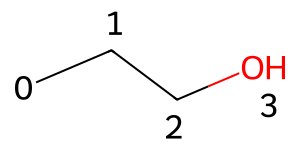

In [26]:
mol = Chem.MolFromSmiles("CCCO")

MORGAN_RADIUS = 2
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, verbose=1)
display(df_morgan_iden)
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

### Constructing a BitInfoMap with Redundant Atom Environments Removed
- `MyGetBitInfoMap()` takes the DataFrame generated by `MyGetMorganIdentifier()` and returns a BitInfoMap.
- When `includeRedundantEnvironments=True` is specified, redundant atom environments are also included in the output.
#### Algorithm Used by MyGetBitInfoMap()
- `MorganAtomEnv`
    - Stores information about accepted atom environments.
    - Each element has the form `(MorganIdentifier, atom index, radius)`.
- `neighborhoods`
    - Stores atomNeighborhoods that have already been accepted.
    - Implemented as a set of atomNeighborhood values.
- For radius=0, all atom environments are accepted.
    - Radius-0 atom environments contain no bonds and are therefore not subject to atomNeighborhood-based redundancy checking.
    - All `(MorganIdentifier, atom index, 0)` entries are added to `MorganAtomEnv`.
- For radius>0, the following procedure is performed at each radius:
    - Create `allNeighborhoodsThisRound`, a list of
      `(atomNeighborhood, MorganIdentifier, atomIdx)`.
    - Sort `allNeighborhoodsThisRound`.
    - Process entries in sorted order.
        - If the atomNeighborhood already exists in `neighborhoods`, the atom environment is discarded.
        - Otherwise:
            - `(MorganIdentifier, atomIdx, radius)` is added to `MorganAtomEnv`.
            - The atomNeighborhood is added to `neighborhoods`.
- Repeat this procedure up to the specified maximum radius.
- Finally, `MorganAtomEnv` is converted into the BitInfoMap format.
    - Keys are Morgan Identifiers and are sorted in ascending order.
    - Values are lists of `(atom index, radius)` tuples.

In [27]:
def MyGetBitInfoMap(df_morgan_iden, includeRedundantEnvironments=False):
    # Create a BitInfoMap with redundant Atom Environments removed (includeRedundantEnvironments=False)
    MorganAtomEnv = [] # List of accepted Morgan Identifiers (identifier, atomIdx, radius)
    neighborhoods = set() # Set of accepted Atom Neighborhoods
    
    radius = int(df_morgan_iden.shape[1]/2) # Maximum radius contained in the input df_morgan_iden
    
    for curr_radius in range(radius):
        if curr_radius == 0: # All radius=0 Atom Environments are retained
            for atomIdx, iden in enumerate(df_morgan_iden[curr_radius]):
                MorganAtomEnv.append( (iden, atomIdx, curr_radius) )
        else: # Redundant Atom Environments must be removed
            allNeighborhoodsThisRound = [] # Store (Atom Neighborhood, Morgan Identifier, center atom index) generated at this radius 
            for atomIdx, (iden, env) in enumerate(zip(df_morgan_iden[curr_radius], df_morgan_iden[str(curr_radius)+"_env"])):
                allNeighborhoodsThisRound.append( (env, iden, atomIdx) )
            allNeighborhoodsThisRound.sort() # Process entries in sorted order 
            for env, iden, atomIdx in allNeighborhoodsThisRound:
                # Exclude redundant Atom Environments and Atom Neighborhoods that have already appeared
                if not includeRedundantEnvironments and (env in neighborhoods): 
                    continue # This Atom Environment is redundant and is therefore discarded
                MorganAtomEnv.append( (iden, atomIdx, curr_radius) ) # Accept and store the Morgan Identifier
                neighborhoods.add(env) # Add the Atom Neighborhood to the set of previously observed Atom Neighborhoods

    BitInfoMap_0 = defaultdict(list) # Store the converted dictionary representation
    for iden, atomIdx, curr_radius in MorganAtomEnv:
        BitInfoMap_0[iden].append( (atomIdx, curr_radius) )
    BitInfoMap = {k: tuple(BitInfoMap_0[k]) for k in sorted(BitInfoMap_0)} # Sort by key and convert values to tuples
    return BitInfoMap

#### Removing Redundant Atom Environments in Propanol
- Redundancy is determined by comparing the Atom Neighborhoods of Atom Environments.
- At radius=0, all Morgan Identifiers are retained.
- At radius=1, all Atom Neighborhoods (`atomNeighborhood`) appear for the first time, so all Morgan Identifiers are retained.
- Now consider the Atom Neighborhoods generated at radius=2.
    - Atom 0 has `atomNeighborhood=3`, which is identical to the Atom Neighborhood of atom 1 at radius=1.
        - Therefore, it is removed.
    - Atom 3 has `atomNeighborhood=6`, which is identical to the Atom Neighborhood of atom 2 at radius=1.
        - Therefore, it is removed.
    - Atom 1 and atom 2 both have `atomNeighborhood=7`.
        - They therefore represent the same Atom Neighborhood.
        - `allNeighborhoodsThisRound` is processed in sorted order.
        - `(7, 1365892349, 2)` is encountered first and is retained.
        - `(7, 2648393034, 1)` is treated as a redundant Atom Environment and is removed.
- The resulting output matches the output generated by RDKit.

Morgan Identifiers and atom neighborhoods generated by MyGetMorganIdentifier


,0,0_env,1,1_env,2,2_env
0,2246728737,0,3542456614,1,1747430757,3
1,2245384272,0,1173125914,3,2648393034,7
2,2245384272,0,4023654873,6,1365892349,7
3,864662311,0,1535166686,4,3729693694,6


Comparison between RDKit and this Python implementation
MorganIdentifier=864662311 ((3, 0),)  my_identifier 864662311 ((3, 0),) True
MorganIdentifier=1173125914 ((1, 1),)  my_identifier 1173125914 ((1, 1),) True
MorganIdentifier=1365892349 ((2, 2),)  my_identifier 1365892349 ((2, 2),) True
MorganIdentifier=1535166686 ((3, 1),)  my_identifier 1535166686 ((3, 1),) True
MorganIdentifier=2245384272 ((1, 0), (2, 0))  my_identifier 2245384272 ((1, 0), (2, 0)) True
MorganIdentifier=2246728737 ((0, 0),)  my_identifier 2246728737 ((0, 0),) True
MorganIdentifier=3542456614 ((0, 1),)  my_identifier 3542456614 ((0, 1),) True
MorganIdentifier=4023654873 ((2, 1),)  my_identifier 4023654873 ((2, 1),) True


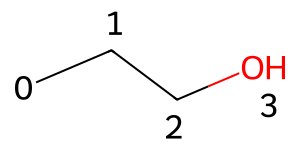

In [28]:
mol = Chem.MolFromSmiles("CCCO")
MORGAN_RADIUS=2
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS)
print("Morgan Identifiers and atom neighborhoods generated by MyGetMorganIdentifier")
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_r2 = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS)
fp = fpgen_r2.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

#### Example: Removing Redundant Atom Environments in Cyclopentane
- At every radius, all atoms have the same Morgan Identifier.
- `allNeighborhoodsThisRound` is processed in sorted order.
- At radius=1, the Atom Neighborhoods are processed in the order `(3, 6, 12, 17, 24)`.
    - Therefore, the order of accepted Atom Environments is:
    - `((1, 1), (2, 1), (3, 1), (0, 1), (4, 1))`
- At radius=2, the Atom Neighborhoods are processed in the order `(15, 23, 27, 29, 30)`.
    - Therefore, the order of accepted Atom Environments is:
    - `((2, 2), (1, 2), (0, 2), (4, 2), (3, 2))`
- The results are identical to those generated by RDKit.

Morgan Identifiers and atom neighborhoods generated by MyGetMorganIdentifier


,0,0_env,1,1_env,2,2_env
0,2968968094,0,2142032900,17,171200514,27
1,2968968094,0,2142032900,3,171200514,23
2,2968968094,0,2142032900,6,171200514,15
3,2968968094,0,2142032900,12,171200514,30
4,2968968094,0,2142032900,24,171200514,29


Comparison between RDKit and this Python implementation
MorganIdentifier=171200514 ((2, 2), (1, 2), (0, 2), (4, 2), (3, 2))  my_identifier 171200514 ((2, 2), (1, 2), (0, 2), (4, 2), (3, 2)) True
MorganIdentifier=2142032900 ((1, 1), (2, 1), (3, 1), (0, 1), (4, 1))  my_identifier 2142032900 ((1, 1), (2, 1), (3, 1), (0, 1), (4, 1)) True
MorganIdentifier=2968968094 ((0, 0), (1, 0), (2, 0), (3, 0), (4, 0))  my_identifier 2968968094 ((0, 0), (1, 0), (2, 0), (3, 0), (4, 0)) True


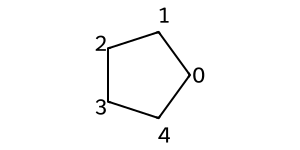

In [29]:
mol = Chem.MolFromSmiles("C1CCCC1")
MORGAN_RADIUS=2
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS)
print("Morgan Identifiers and atom neighborhoods generated by MyGetMorganIdentifier")
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_r2 = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS)
fp = fpgen_r2.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

#### Including Redundant Atom Environments
- Let us use cyclobutane as an example.
- In RDKit, redundant Atom Environments can be retained by specifying `includeRedundantEnvironments=True` as follows.
    - `rdFingerprintGenerator.GetMorganGenerator( radius=MORGAN_RADIUS, includeRedundantEnvironments=True )`
- The implementation in this notebook uses the same option.
    - `MyGetBitInfoMap( df_morgan_iden, includeRedundantEnvironments=True )`
- The resulting output is identical to the output generated by RDKit.
    - Redundant Atom Environments at radius=2, which are removed when `includeRedundantEnvironments=False` (the default), are also included in the output.

Default: includeRedundantEnvironments=False
Comparison between RDKit and this Python implementation
MorganIdentifier=171200514  ((0, 2),)  my_identifier 171200514 ((0, 2),) True
MorganIdentifier=2142032900  ((1, 1), (2, 1), (0, 1), (3, 1))  my_identifier 2142032900 ((1, 1), (2, 1), (0, 1), (3, 1)) True
MorganIdentifier=2968968094  ((0, 0), (1, 0), (2, 0), (3, 0))  my_identifier 2968968094 ((0, 0), (1, 0), (2, 0), (3, 0)) True
includeRedundantEnvironments=True
Comparison between RDKit and this Python implementation
MorganIdentifier=171200514  ((0, 2), (1, 2), (2, 2), (3, 2))  my_identifier 171200514 ((0, 2), (1, 2), (2, 2), (3, 2)) True
MorganIdentifier=2142032900  ((1, 1), (2, 1), (0, 1), (3, 1))  my_identifier 2142032900 ((1, 1), (2, 1), (0, 1), (3, 1)) True
MorganIdentifier=2968968094  ((0, 0), (1, 0), (2, 0), (3, 0))  my_identifier 2968968094 ((0, 0), (1, 0), (2, 0), (3, 0)) True


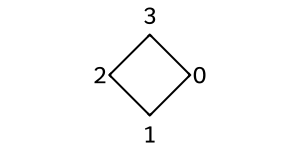

In [30]:
mol = Chem.MolFromSmiles("C1CCC1")
MORGAN_RADIUS=2
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS)

print("Default: includeRedundantEnvironments=False")
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS)
fp = fpgen.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd}  {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")

print("includeRedundantEnvironments=True")
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden, includeRedundantEnvironments=True)
print("Comparison between RDKit and this Python implementation")
fpgen_redun = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeRedundantEnvironments=True)
fp = fpgen_redun.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd}  {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")

d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

## 4. Converting Morgan Fingerprints to a Fixed-Length Representation
- The Morgan Fingerprints obtained so far use Morgan Identifiers directly, resulting in a very large feature space.
- This creates several challenges when applying them directly to machine learning or similarity calculations.
    - Morgan Identifiers are represented as unsigned 32-bit integers.
        - Therefore, they can theoretically take up to `2**32` different values.
    - In practice, only a small fraction of these identifiers appear in any given molecule.
        - As a result, the fingerprint becomes an extremely sparse representation in which most entries are zero.
        - RDKit's `GetSparseCountFingerprint()` returns a sparse fingerprint containing occurrence counts.
        - RDKit's `GetSparseFingerprint()` returns a sparse fingerprint containing only presence or absence information.
- For this reason, fixed-length Morgan Fingerprints are widely used in practical applications.
- A fixed-length representation is obtained by taking the remainder when dividing each Morgan Identifier by `fpSize`.

### Example: RDKit Output for Cyclopentane
- Cyclopentane contains Atom Environments corresponding to the following Morgan Identifiers:

```text
171200514
2142032900
2968968094
```

- To generate a fingerprint with a length of 2048 bits, each Morgan Identifier is divided by 2048 and the remainder is calculated.

```text
171200514  % 2048 = 2
2142032900 % 2048 = 1028
2968968094 % 2048 = 926
```

- Therefore, these Atom Environments are assigned to bit positions 2, 1028, and 926 of the fixed-length fingerprint.
- In a bit-vector fingerprint:
    - The corresponding bit is set to 1 if the Atom Environment is present.
    - Otherwise, the bit remains 0.
- Let us generate a 2048-bit Morgan Fingerprint using RDKit.
    - Bit positions 2, 926, and 1028 are set to 1.
    - All other bits remain 0.

In [31]:
mol = Chem.MolFromSmiles("C1CCCC1")
MORGAN_RADIUS=2
FPSIZE=2048
fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS)
fp = fpgen.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for key in BitInfoMap.keys():
    print(f"MorganIdentifier= {key} % {FPSIZE} = {key % FPSIZE} (Identifier at fpsize={FPSIZE})")
fpgen_2048 = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, fpSize=FPSIZE)
fp_2048 = fpgen_2048.GetFingerprint(mol)
print(f"RDKit {FPSIZE} bits Morgan Fingerprint")
print(fp_2048.ToBitString())

MorganIdentifier= 171200514 % 2048 = 2 (Identifier at fpsize=2048)
MorganIdentifier= 2142032900 % 2048 = 1028 (Identifier at fpsize=2048)
MorganIdentifier= 2968968094 % 2048 = 926 (Identifier at fpsize=2048)
RDKit 2048 bits Morgan Fingerprint
0010000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000

### Converting a BitInfoMap to a Fixed-Length Bit Vector
- `MyGetFingerprint()` is a function that generates an `ExplicitBitVect` from a BitInfoMap, equivalent to the object returned by RDKit's `GetFingerprint()`.
- The fingerprint length is specified using `fpSize`.
- For each Morgan Identifier contained in the BitInfoMap, the bit at position `MorganIdentifier % fpSize` is set to 1.
- In this way, a fixed-length Morgan Fingerprint is generated.

In [32]:
def MyGetFingerprint(BitInfoMap, fpSize):
    # Create a fixed-length fingerprint (ExplicitBitVect) from a BitInfoMap
    bv = ExplicitBitVect(fpSize)
    for key in BitInfoMap:
        bv.SetBit(key % fpSize) # Set the bit corresponding to MorganIdentifier % fpSize to 1
    return bv

- Let us generate a 2048-bit fingerprint for cyclopentane from the `MyBitInfoMap` created by our Python implementation.
- Although the output is difficult to inspect visually, it is identical to the fingerprint generated by RDKit.
- The expression `fp_2048 == Myfp_2048` evaluates to `True`.

In [33]:
mol = Chem.MolFromSmiles("C1CCCC1")
MORGAN_RADIUS=2
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
Myfp_2048 = MyGetFingerprint(MyBitInfoMap, 2048)
print(Myfp_2048.ToBitString())
print(f"fp_2048 == Myfp_2048 -> {fp_2048 == Myfp_2048}")

0010000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000010000000000000000000000000000000000000000000000000000000000000000000000000

### Bit Collisions
- Converting Morgan Identifiers into a fixed-length fingerprint introduces the possibility of bit collisions.
- A bit collision occurs when different Morgan Identifiers are assigned to the same bit position.
    - This phenomenon is sometimes referred to as a hash collision.
- A bit collision occurs when different Morgan Identifiers, generated from different Atom Environments, are assigned to the same bit position during conversion to a fixed-length fingerprint.
#### Example of a Bit Collision
- As a practical example, consider the following three compounds obtained from ZINC15.
    - https://zinc15.docking.org/majorclasses/ion_channel/substances/subsets/fda/
- Stereochemical information is not used in this example.
- The following three compounds contain different Atom Environments.
    - ZINC000004474460 `C=C1CC[C@H](O)C/C1=C/C=C1/CCC[C@]2(C)[C@@H]([C@H](C)CCCC(C)C)CC[C@@H]12`
    - ZINC000000897085 `O[C@@H](c1cc(C(F)(F)F)nc2c(C(F)(F)F)cccc12)[C@H]1CCCCN1`
    - ZINC000000075126 `Cc1nccn1C[C@@H]1CCc2c(c3ccccc3n2C)C1=O`
- However, when converted into a 2048-bit fingerprint, each compound contains an Atom Environment that is mapped to bit position 1808.
- Inspection of the results shows that different Morgan Identifiers are assigned to the same bit position, 1808.
- As a result, bit 1808 is set to 1 in the fingerprints of all three compounds.

ZINC000000075126
MorganIdentifier= 3109601040 ((5, 2),)  (3109601040 % 2048 = 1808)
fp_2048.GetBit(1808)= True


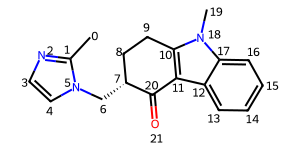

ZINC000000897085
MorganIdentifier= 298374928 ((20, 1),)  (298374928 % 2048 = 1808)
fp_2048.GetBit(1808)= True


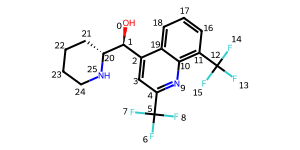

ZINC000004474460
MorganIdentifier= 1167517456 ((17, 2),)  (1167517456 % 2048 = 1808)
fp_2048.GetBit(1808)= True


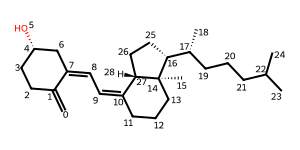

In [34]:
MORGAN_RADIUS=2
FPSIZE=2048
fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS)
zinc_datas = [ ("ZINC000000075126", "Cc1nccn1C[C@@H]1CCc2c(c3ccccc3n2C)C1=O"),
              ("ZINC000000897085", "O[C@@H](c1cc(C(F)(F)F)nc2c(C(F)(F)F)cccc12)[C@H]1CCCCN1"),
              ("ZINC000004474460", "C=C1CC[C@H](O)C/C1=C/C=C1/CCC[C@]2(C)[C@@H]([C@H](C)CCCC(C)C)CC[C@@H]12") ]
for (zinc_id, zinc_smiles) in zinc_datas:
    print(zinc_id)
    mol = Chem.MolFromSmiles(zinc_smiles)
    fp = fpgen.GetSparseCountFingerprint(mol, additionalOutput=ao)
    BitInfoMap = ao.GetBitInfoMap()
    for key in BitInfoMap.keys():
        if key % FPSIZE == 1808:
            print(f"MorganIdentifier= {key} {BitInfoMap[key]}  ({key} % {FPSIZE} = {key % FPSIZE})")
    fpgen_2048 = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, fpSize=FPSIZE)
    fp_2048 = fpgen_2048.GetFingerprint(mol)
    print(f"fp_2048.GetBit(1808)= {fp_2048.GetBit(1808)}")
    d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
    d2d.drawOptions().addAtomIndices = True
    d2d.drawOptions().annotationFontScale =1.0
    d2d.DrawMolecule(mol)
    d2d.FinishDrawing()
    display(SVG(d2d.GetDrawingText()))

- Thus, converting Morgan Identifiers to a fixed-length representation inevitably introduces bit collisions.
- When a bit collision occurs:
    - Different Atom Environments are merged into the same bit.
    - The original Atom Environments cannot be reconstructed uniquely from the fixed-length fingerprint.
    - Molecular similarity calculations may be affected slightly.
- On the other hand, converting fingerprints to a fixed length produces compact and efficient descriptors, which is why they are widely used in practice.
- When performing detailed analyses using fixed-length Morgan Fingerprints, it is important to keep the existence of bit collisions in mind when interpreting the results.

## 5. Examples of Stereochemical and Isotopic Information
- Finally, let us examine Morgan Fingerprints for molecules containing geometric isomers, enantiomers, and isotopes.
- These examples illustrate how stereochemical and isotopic information is incorporated into Morgan Identifiers.
- We also verify that the Morgan Identifiers calculated by this Python implementation match those generated by RDKit.

### Including Stereochemical Information
- To generate Morgan Fingerprints that include stereochemical information in RDKit, specify `includeChirality=True` as shown below.
    - `rdFingerprintGenerator.GetMorganGenerator( radius=2, includeChirality=True )`
- The implementation in this notebook uses the same option.
    - `MyGetMorganIdentifier( mol, radius=2, includeChirality=True, verbose=1)`
- When `includeChirality=False` (the default), stereochemical information is not used when calculating Morgan Identifiers.

### Calculating Morgan Identifiers for Geometric Isomers

- As an example, consider trans-2-pentene (`C\C=C\CC`) and cis-2-pentene (`C\C=C/CC`).
- The following examples show the results when stereochemical information is included.
    - Example of `C\C=C\CC`
    - Example of `C\C=C/CC`
- Comparing the two results shows that the Bond Invariants associated with the double bond are different.
- Because E/Z stereochemistry is incorporated into Bond Invariants, the Morgan Identifiers at radius=1 and radius=2 also differ.
- In contrast, Atom Environments not affected by stereochemistry produce identical Morgan Identifiers.
- In both cases, the results generated by this Python implementation agree with those generated by RDKit.

Example of C\C=C\CC
MyGetMorganIdentifier: radius=2 includeChirality=True
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2246703798 components=[6, 3, 1, 0, 0]
atom=2 MorganIdentifier=2246703798 components=[6, 3, 1, 0, 0]
atom=3 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=4 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
radius=1
atom=0 MorganIdentifier=3545353036 Neighbor=[(1, 2246703798)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=736708276 Neighbor=[(1, 2246728737), (125, 2246703798)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=530222952 Neighbor=[(1, 2245384272), (125, 2246703798)] LooksChiral=0 atomNeighborhood=0b110
atom=3 MorganIdentifier=2065620398 Neighbor=[(1, 2246703798), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b1100
atom=4 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1000
radius=2
atom=0 MorganIdentifier=2402080175 Neighbo

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3545353036,1,2402080175,3
1,2246703798,0,736708276,3,2102851056,7
2,2246703798,0,530222952,6,1741163965,15
3,2245384272,0,2065620398,12,3406717757,14
4,2246728737,0,3542456614,8,328495345,12


Comparison between RDKit and this Python implementation
MorganIdentifier=530222952 ((2, 1),)  my_identifier 530222952 ((2, 1),) True
MorganIdentifier=736708276 ((1, 1),)  my_identifier 736708276 ((1, 1),) True
MorganIdentifier=1741163965 ((2, 2),)  my_identifier 1741163965 ((2, 2),) True
MorganIdentifier=2065620398 ((3, 1),)  my_identifier 2065620398 ((3, 1),) True
MorganIdentifier=2102851056 ((1, 2),)  my_identifier 2102851056 ((1, 2),) True
MorganIdentifier=2245384272 ((3, 0),)  my_identifier 2245384272 ((3, 0),) True
MorganIdentifier=2246703798 ((1, 0), (2, 0))  my_identifier 2246703798 ((1, 0), (2, 0)) True
MorganIdentifier=2246728737 ((0, 0), (4, 0))  my_identifier 2246728737 ((0, 0), (4, 0)) True
MorganIdentifier=3406717757 ((3, 2),)  my_identifier 3406717757 ((3, 2),) True
MorganIdentifier=3542456614 ((4, 1),)  my_identifier 3542456614 ((4, 1),) True
MorganIdentifier=3545353036 ((0, 1),)  my_identifier 3545353036 ((0, 1),) True


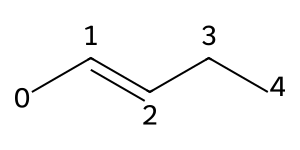

In [35]:
mol = Chem.MolFromSmiles("C\C=C\CC")
print("Example of C\C=C\CC")
includeChirality=True
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, includeChirality=includeChirality, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeChirality=includeChirality)
fp = fpgen_chiral.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

Example of C\C=C/CC
MyGetMorganIdentifier: radius=2 includeChirality=True
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2246703798 components=[6, 3, 1, 0, 0]
atom=2 MorganIdentifier=2246703798 components=[6, 3, 1, 0, 0]
atom=3 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=4 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
radius=1
atom=0 MorganIdentifier=3545353036 Neighbor=[(1, 2246703798)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=736708341 Neighbor=[(1, 2246728737), (124, 2246703798)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=530222891 Neighbor=[(1, 2245384272), (124, 2246703798)] LooksChiral=0 atomNeighborhood=0b110
atom=3 MorganIdentifier=2065620398 Neighbor=[(1, 2246703798), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b1100
atom=4 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1000
radius=2
atom=0 MorganIdentifier=2402080116 Neighbo

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3545353036,1,2402080116,3
1,2246703798,0,736708341,3,2100976915,7
2,2246703798,0,530222891,6,1741682072,15
3,2245384272,0,2065620398,12,3406476695,14
4,2246728737,0,3542456614,8,328495345,12


Comparison between RDKit and this Python implementation
MorganIdentifier=530222891 ((2, 1),)  my_identifier 530222891 ((2, 1),) True
MorganIdentifier=736708341 ((1, 1),)  my_identifier 736708341 ((1, 1),) True
MorganIdentifier=1741682072 ((2, 2),)  my_identifier 1741682072 ((2, 2),) True
MorganIdentifier=2065620398 ((3, 1),)  my_identifier 2065620398 ((3, 1),) True
MorganIdentifier=2100976915 ((1, 2),)  my_identifier 2100976915 ((1, 2),) True
MorganIdentifier=2245384272 ((3, 0),)  my_identifier 2245384272 ((3, 0),) True
MorganIdentifier=2246703798 ((1, 0), (2, 0))  my_identifier 2246703798 ((1, 0), (2, 0)) True
MorganIdentifier=2246728737 ((0, 0), (4, 0))  my_identifier 2246728737 ((0, 0), (4, 0)) True
MorganIdentifier=3406476695 ((3, 2),)  my_identifier 3406476695 ((3, 2),) True
MorganIdentifier=3542456614 ((4, 1),)  my_identifier 3542456614 ((4, 1),) True
MorganIdentifier=3545353036 ((0, 1),)  my_identifier 3545353036 ((0, 1),) True


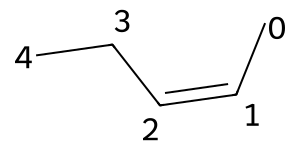

In [36]:
mol = Chem.MolFromSmiles("C\C=C/CC")
print("Example of C\\C=C/CC")
includeChirality=True
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, includeChirality=includeChirality, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeChirality=includeChirality)
fp = fpgen_chiral.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

#### Without Stereochemical Information
- Next, let us examine the result obtained with `includeChirality=False`.
    - `C\C=C/CC with includeChirality=False`
- In this case, E/Z stereochemistry is ignored.
- The double bond is treated simply as a double bond.
- As a result, the cis and trans isomers generate the same Morgan Identifiers.
- Although the resulting Morgan Identifiers differ from those generated when stereochemistry is included, they are identical to the values produced by RDKit.

C\C=C/CC with includeChirality=False
MyGetMorganIdentifier: radius=2 includeChirality=False
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2246703798 components=[6, 3, 1, 0, 0]
atom=2 MorganIdentifier=2246703798 components=[6, 3, 1, 0, 0]
atom=3 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=4 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
radius=1
atom=0 MorganIdentifier=3545353036 Neighbor=[(1, 2246703798)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=736731344 Neighbor=[(1, 2246728737), (2, 2246703798)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=530246988 Neighbor=[(1, 2245384272), (2, 2246703798)] LooksChiral=0 atomNeighborhood=0b110
atom=3 MorganIdentifier=2065620398 Neighbor=[(1, 2246703798), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b1100
atom=4 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1000
radius=2
atom=0 MorganIdentifier=2402

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3545353036,1,2402058131,3
1,2246703798,0,736731344,3,1738749468,7
2,2246703798,0,530246988,6,1761408361,15
3,2245384272,0,2065620398,12,3406031982,14
4,2246728737,0,3542456614,8,328495345,12


Comparison between RDKit and this Python implementation
MorganIdentifier=530246988 ((2, 1),)  my_identifier 530246988 ((2, 1),) True
MorganIdentifier=736731344 ((1, 1),)  my_identifier 736731344 ((1, 1),) True
MorganIdentifier=1738749468 ((1, 2),)  my_identifier 1738749468 ((1, 2),) True
MorganIdentifier=1761408361 ((2, 2),)  my_identifier 1761408361 ((2, 2),) True
MorganIdentifier=2065620398 ((3, 1),)  my_identifier 2065620398 ((3, 1),) True
MorganIdentifier=2245384272 ((3, 0),)  my_identifier 2245384272 ((3, 0),) True
MorganIdentifier=2246703798 ((1, 0), (2, 0))  my_identifier 2246703798 ((1, 0), (2, 0)) True
MorganIdentifier=2246728737 ((0, 0), (4, 0))  my_identifier 2246728737 ((0, 0), (4, 0)) True
MorganIdentifier=3406031982 ((3, 2),)  my_identifier 3406031982 ((3, 2),) True
MorganIdentifier=3542456614 ((4, 1),)  my_identifier 3542456614 ((4, 1),) True
MorganIdentifier=3545353036 ((0, 1),)  my_identifier 3545353036 ((0, 1),) True


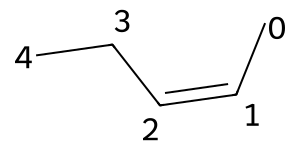

In [37]:
mol = Chem.MolFromSmiles("C\C=C/CC")
print("C\\C=C/CC with includeChirality=False")
includeChirality=False
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, includeChirality=includeChirality, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeChirality=includeChirality)
fp = fpgen_chiral.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

### Morgan Identifier Calculation for Enantiomers
- Next, consider the enantiomeric pair `CC[C@@](F)(Cl)Br` and `CC[C@](F)(Cl)Br`.
- The following examples show the results when stereochemical information is included.
    - Example of `CC[C@@](F)(Cl)Br`
    - Example of `CC[C@](F)(Cl)Br`
- The chiral center has a different `LooksChiral` value in each molecule.
    - R configuration → 3
    - S configuration → 2
- This difference is incorporated into the Morgan Identifier calculation.
- Consequently, the Morgan Identifiers generated at radius=1 and radius=2 are different.
- In both cases, the results generated by this Python implementation agree with those generated by RDKit.

Example of CC[C@@](F)(Cl)Br
MyGetMorganIdentifier: radius=2 includeChirality=True
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=2 MorganIdentifier=2245277810 components=[6, 4, 0, 0, 0]
atom=3 MorganIdentifier=882399112 components=[9, 1, 0, 0, 0]
atom=4 MorganIdentifier=1016841875 components=[17, 1, 0, 0, 0]
atom=5 MorganIdentifier=3612926680 components=[35, 1, 0, 0, 0]
radius=1
atom=0 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=1505769767 Neighbor=[(1, 2245277810), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=3821193030 Neighbor=[(1, 882399112), (1, 1016841875), (1, 2245384272), (1, 3612926680)] LooksChiral=3 atomNeighborhood=0b11110
atom=3 MorganIdentifier=485463469 Neighbor=[(1, 2245277810)] LooksChiral=0 atomNeighborhood=0b100
atom=4 MorganIdentifier=170894115 Neighbor=[(1, 2245277810)] Looks

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3542456614,1,880090986,3
1,2245384272,0,1505769767,3,4067363791,31
2,2245277810,0,3821193030,30,2111933619,31
3,882399112,0,485463469,4,4214232094,30
4,1016841875,0,170894115,8,588079498,30
5,3612926680,0,325281617,16,1798477929,30


Comparison between RDKit and this Python implementation
MorganIdentifier=170894115 ((4, 1),)  my_identifier 170894115 ((4, 1),) True
MorganIdentifier=325281617 ((5, 1),)  my_identifier 325281617 ((5, 1),) True
MorganIdentifier=485463469 ((3, 1),)  my_identifier 485463469 ((3, 1),) True
MorganIdentifier=882399112 ((3, 0),)  my_identifier 882399112 ((3, 0),) True
MorganIdentifier=1016841875 ((4, 0),)  my_identifier 1016841875 ((4, 0),) True
MorganIdentifier=1505769767 ((1, 1),)  my_identifier 1505769767 ((1, 1),) True
MorganIdentifier=2111933619 ((2, 2),)  my_identifier 2111933619 ((2, 2),) True
MorganIdentifier=2245277810 ((2, 0),)  my_identifier 2245277810 ((2, 0),) True
MorganIdentifier=2245384272 ((1, 0),)  my_identifier 2245384272 ((1, 0),) True
MorganIdentifier=2246728737 ((0, 0),)  my_identifier 2246728737 ((0, 0),) True
MorganIdentifier=3542456614 ((0, 1),)  my_identifier 3542456614 ((0, 1),) True
MorganIdentifier=3612926680 ((5, 0),)  my_identifier 3612926680 ((5, 0),) True
Morg

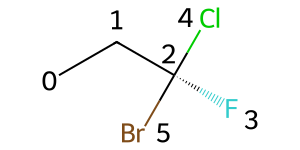

In [38]:
mol = Chem.MolFromSmiles("CC[C@@](F)(Cl)Br")
print("Example of CC[C@@](F)(Cl)Br")
includeChirality=True
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, includeChirality=includeChirality, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeChirality=includeChirality)
fp = fpgen_chiral.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

Example of CC[C@](F)(Cl)Br
MyGetMorganIdentifier: radius=2 includeChirality=True
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=2 MorganIdentifier=2245277810 components=[6, 4, 0, 0, 0]
atom=3 MorganIdentifier=882399112 components=[9, 1, 0, 0, 0]
atom=4 MorganIdentifier=1016841875 components=[17, 1, 0, 0, 0]
atom=5 MorganIdentifier=3612926680 components=[35, 1, 0, 0, 0]
radius=1
atom=0 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=1505769767 Neighbor=[(1, 2245277810), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=3821193029 Neighbor=[(1, 882399112), (1, 1016841875), (1, 2245384272), (1, 3612926680)] LooksChiral=2 atomNeighborhood=0b11110
atom=3 MorganIdentifier=485463469 Neighbor=[(1, 2245277810)] LooksChiral=0 atomNeighborhood=0b100
atom=4 MorganIdentifier=170894115 Neighbor=[(1, 2245277810)] LooksC

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3542456614,1,880090986,3
1,2245384272,0,1505769767,3,4067363788,31
2,2245277810,0,3821193029,30,3499573409,31
3,882399112,0,485463469,4,4214232095,30
4,1016841875,0,170894115,8,588079499,30
5,3612926680,0,325281617,16,1798477930,30


Comparison between RDKit and this Python implementation
MorganIdentifier=170894115 ((4, 1),)  my_identifier 170894115 ((4, 1),) True
MorganIdentifier=325281617 ((5, 1),)  my_identifier 325281617 ((5, 1),) True
MorganIdentifier=485463469 ((3, 1),)  my_identifier 485463469 ((3, 1),) True
MorganIdentifier=882399112 ((3, 0),)  my_identifier 882399112 ((3, 0),) True
MorganIdentifier=1016841875 ((4, 0),)  my_identifier 1016841875 ((4, 0),) True
MorganIdentifier=1505769767 ((1, 1),)  my_identifier 1505769767 ((1, 1),) True
MorganIdentifier=2245277810 ((2, 0),)  my_identifier 2245277810 ((2, 0),) True
MorganIdentifier=2245384272 ((1, 0),)  my_identifier 2245384272 ((1, 0),) True
MorganIdentifier=2246728737 ((0, 0),)  my_identifier 2246728737 ((0, 0),) True
MorganIdentifier=3499573409 ((2, 2),)  my_identifier 3499573409 ((2, 2),) True
MorganIdentifier=3542456614 ((0, 1),)  my_identifier 3542456614 ((0, 1),) True
MorganIdentifier=3612926680 ((5, 0),)  my_identifier 3612926680 ((5, 0),) True
Morg

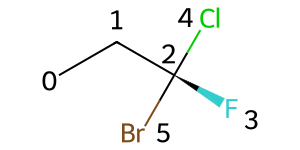

In [39]:
mol = Chem.MolFromSmiles("CC[C@](F)(Cl)Br")
print("Example of CC[C@](F)(Cl)Br")
includeChirality=True
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, includeChirality=includeChirality, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeChirality=includeChirality)
fp = fpgen_chiral.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

#### Without Stereochemical Information
- Next, let us examine the result obtained with `includeChirality=False`.
    - `CC[C@](F)(Cl)Br with includeChirality=False`
- When `includeChirality=False`, stereochemical information at stereocenters is not used.
- As a result, enantiomeric molecules generate the same Morgan Identifiers.
- Compared with the stereochemistry-aware calculation, the set of retained Atom Environments may also change after redundant Atom Environments are removed.
- In this example, the order in which radius=2 Atom Environments are processed changes, resulting in a different set of Atom Environments being retained in the BitInfoMap.
- The output remains identical to that produced by RDKit.

CC[C@](F)(Cl)Br with includeChirality=False
MyGetMorganIdentifier: radius=2 includeChirality=False
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2245384272 components=[6, 4, 2, 0, 0]
atom=2 MorganIdentifier=2245277810 components=[6, 4, 0, 0, 0]
atom=3 MorganIdentifier=882399112 components=[9, 1, 0, 0, 0]
atom=4 MorganIdentifier=1016841875 components=[17, 1, 0, 0, 0]
atom=5 MorganIdentifier=3612926680 components=[35, 1, 0, 0, 0]
radius=1
atom=0 MorganIdentifier=3542456614 Neighbor=[(1, 2245384272)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=1505769767 Neighbor=[(1, 2245277810), (1, 2246728737)] LooksChiral=0 atomNeighborhood=0b11
atom=2 MorganIdentifier=1408502088 Neighbor=[(1, 882399112), (1, 1016841875), (1, 2245384272), (1, 3612926680)] LooksChiral=0 atomNeighborhood=0b11110
atom=3 MorganIdentifier=485463469 Neighbor=[(1, 2245277810)] LooksChiral=0 atomNeighborhood=0b100
atom=4 MorganIdentifier=170894115 Neighbor=[(1, 2

,0,0_env,1,1_env,2,2_env
0,2246728737,0,3542456614,1,880090986,3
1,2245384272,0,1505769767,3,2041435466,31
2,2245277810,0,1408502088,30,4047137456,31
3,882399112,0,485463469,4,1799541264,30
4,1016841875,0,170894115,8,3017679752,30
5,3612926680,0,325281617,16,3681409643,30


Comparison between RDKit and this Python implementation
MorganIdentifier=170894115 ((4, 1),)  my_identifier 170894115 ((4, 1),) True
MorganIdentifier=325281617 ((5, 1),)  my_identifier 325281617 ((5, 1),) True
MorganIdentifier=485463469 ((3, 1),)  my_identifier 485463469 ((3, 1),) True
MorganIdentifier=882399112 ((3, 0),)  my_identifier 882399112 ((3, 0),) True
MorganIdentifier=1016841875 ((4, 0),)  my_identifier 1016841875 ((4, 0),) True
MorganIdentifier=1408502088 ((2, 1),)  my_identifier 1408502088 ((2, 1),) True
MorganIdentifier=1505769767 ((1, 1),)  my_identifier 1505769767 ((1, 1),) True
MorganIdentifier=2041435466 ((1, 2),)  my_identifier 2041435466 ((1, 2),) True
MorganIdentifier=2245277810 ((2, 0),)  my_identifier 2245277810 ((2, 0),) True
MorganIdentifier=2245384272 ((1, 0),)  my_identifier 2245384272 ((1, 0),) True
MorganIdentifier=2246728737 ((0, 0),)  my_identifier 2246728737 ((0, 0),) True
MorganIdentifier=3542456614 ((0, 1),)  my_identifier 3542456614 ((0, 1),) True
Morg

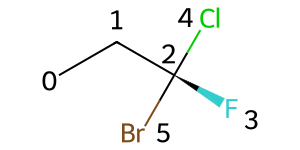

In [40]:
mol = Chem.MolFromSmiles("CC[C@](F)(Cl)Br")
print("CC[C@](F)(Cl)Br with includeChirality=False")
includeChirality=False # Stereochemical information is not used
df_morgan_iden = MyGetMorganIdentifier(mol, radius=MORGAN_RADIUS, includeChirality=includeChirality, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen_chiral = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, includeChirality=includeChirality)
fp = fpgen_chiral.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

### Including Isotope Information
- Finally, let us consider a molecule containing isotopes: `CC([13CH3])[14CH3]`.
- Isotope information is incorporated through the difference between the actual atomic mass and the standard atomic mass.
- The following value is used in this notebook:
    - `delta_mass = int(actual_mass - standard_mass)`
- Because `int()` is used, the fractional part is discarded.
- As a result:
    - atom 2 (`[13C]`) has the same `delta_mass=0` as a normal `[12C]` atom.
    - Atom 3 (`[14C]`) has `delta_mass=1`.
- Therefore, Atom 2 (`[13C]`) and Atom 0 (`[12C]`) generate the same Morgan Identifier.
- In contrast, Atom 3 (`[14C]`) generates a different Morgan Identifier.
- The results produced by this Python implementation are identical to those generated by RDKit.

Example of CC([13CH3])[14CH3]
delta_mass
atom= 0 Mass= 12.011  delta_mass= int(12.011 - 12.011) = int(0.0) = 0
atom= 1 Mass= 12.011  delta_mass= int(12.011 - 12.011) = int(0.0) = 0
atom= 2 Mass= 13.00335484  delta_mass= int(13.00335484 - 12.011) = int(0.9923548400000008) = 0
atom= 3 Mass= 14.00324199  delta_mass= int(14.00324199 - 12.011) = int(1.9922419900000001) = 1
MyGetMorganIdentifier: radius=1 includeChirality=False
radius=0
atom=0 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=1 MorganIdentifier=2245273601 components=[6, 4, 1, 0, 0]
atom=2 MorganIdentifier=2246728737 components=[6, 4, 3, 0, 0]
atom=3 MorganIdentifier=2246728742 components=[6, 4, 3, 0, 1]
radius=1
atom=0 MorganIdentifier=3537119515 Neighbor=[(1, 2245273601)] LooksChiral=0 atomNeighborhood=0b1
atom=1 MorganIdentifier=1511968924 Neighbor=[(1, 2246728737), (1, 2246728737), (1, 2246728742)] LooksChiral=0 atomNeighborhood=0b111
atom=2 MorganIdentifier=3537119515 Neighbor=[(1, 2245273601)] LooksChiral=0 at

,0,0_env,1,1_env
0,2246728737,0,3537119515,1
1,2245273601,0,1511968924,7
2,2246728737,0,3537119515,2
3,2246728742,0,3537120221,4


Comparison between RDKit and this Python implementation
MorganIdentifier=1511968924 ((1, 1),)  my_identifier 1511968924 ((1, 1),) True
MorganIdentifier=2245273601 ((1, 0),)  my_identifier 2245273601 ((1, 0),) True
MorganIdentifier=2246728737 ((0, 0), (2, 0))  my_identifier 2246728737 ((0, 0), (2, 0)) True
MorganIdentifier=2246728742 ((3, 0),)  my_identifier 2246728742 ((3, 0),) True
MorganIdentifier=3537119515 ((0, 1), (2, 1))  my_identifier 3537119515 ((0, 1), (2, 1)) True
MorganIdentifier=3537120221 ((3, 1),)  my_identifier 3537120221 ((3, 1),) True


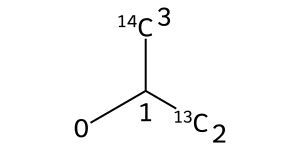

In [41]:
mol = Chem.MolFromSmiles("CC([13CH3])[14CH3]")
print("Example of CC([13CH3])[14CH3]")
ptable = Chem.GetPeriodicTable()
print("delta_mass")
for atom in mol.GetAtoms():
    mass = atom.GetMass()
    std_mass = ptable.GetAtomicWeight(atom.GetAtomicNum())
    print(f"atom= {atom.GetIdx()} Mass= {mass}  delta_mass= int({mass} - {std_mass}) = int({mass-std_mass}) = {int(mass-std_mass)}")

curr_radius = 1
df_morgan_iden = MyGetMorganIdentifier(mol, radius=curr_radius, verbose=1)
display(df_morgan_iden)
MyBitInfoMap = MyGetBitInfoMap(df_morgan_iden)
print("Comparison between RDKit and this Python implementation")
fpgen2 = rdFingerprintGenerator.GetMorganGenerator(radius=curr_radius)
fp = fpgen2.GetSparseCountFingerprint(mol, additionalOutput=ao)
BitInfoMap = ao.GetBitInfoMap()
for rd, my in zip(BitInfoMap, MyBitInfoMap):
    print(f"MorganIdentifier={rd} {BitInfoMap[rd]}  my_identifier {my} {MyBitInfoMap[my]} {rd==my and BitInfoMap[rd]==MyBitInfoMap[my]}")
d2d = rdMolDraw2D.MolDraw2DSVG(300, 150)
d2d.drawOptions().addAtomIndices = True
d2d.drawOptions().annotationFontScale =1.0
d2d.DrawMolecule(mol)
d2d.FinishDrawing()
display(SVG(d2d.GetDrawingText()))

### Closing Remarks
- To better understand how Morgan Fingerprints are generated, I created this Python implementation while studying the RDKit source code.
- Reimplementing the algorithm helped me gain a much clearer understanding of each step, from Atom Invariant generation and Morgan Identifier calculation to redundancy removal and fixed-length fingerprint construction.
- Being able to inspect intermediate results made it easier to see how the fingerprint is built internally and how each stage contributes to the final result.
- This implementation is only a personal learning exercise, but I hope it may be useful to others who are also interested in understanding how Morgan Fingerprints work under the hood.